## Overview of MEG/EEG analysis with MNE-Python

Covering: oading data, epoching, averaging, plotting, and estimating cortical activity from sensor data

Data structures:  Raw, Epochs, Evoked, and SourceEstimate

In [2]:
import numpy as np

import mne

### Loading data

the data used here is called sample, and is one of the example datasets. it containts MEG, EEG, and structured fMRI data of a single participant of an audiovisual experiment.

the function  ```mne.datasets.sample.data_path``` willl automatically download the dataset if it's not available for some reason

the `read_raw_fif` will read the raw data (just like `read_csv` would), and gives some basic info

In [4]:
sample_data_folder = mne.datasets.sample.data_path()
sample_data_raw_file = (
    sample_data_folder / "MEG" / "sample" / "sample_audvis_filt-0-40_raw.fif"
)
raw = mne.io.read_raw_fif(sample_data_raw_file)

Opening raw data file /Users/marinad/mne_data/MNE-sample-data/MEG/sample/sample_audvis_filt-0-40_raw.fif...
    Read a total of 4 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
        Average EEG reference (1 x 60)  idle
    Range : 6450 ... 48149 =     42.956 ...   320.665 secs
Ready.


more info about the raw data can be found by simply printing it or using the `info` attribute

In [5]:
print(raw)

<Raw | sample_audvis_filt-0-40_raw.fif, 376 x 41700 (277.7 s), ~3.2 MiB, data not loaded>


In [6]:
print(raw.info)

<Info | 15 non-empty values
 bads: 2 items (MEG 2443, EEG 053)
 ch_names: MEG 0113, MEG 0112, MEG 0111, MEG 0122, MEG 0123, MEG 0121, MEG ...
 chs: 204 Gradiometers, 102 Magnetometers, 9 Stimulus, 60 EEG, 1 EOG
 custom_ref_applied: False
 dev_head_t: MEG device -> head transform
 dig: 146 items (3 Cardinal, 4 HPI, 61 EEG, 78 Extra)
 file_id: 4 items (dict)
 highpass: 0.1 Hz
 hpi_meas: 1 item (list)
 hpi_results: 1 item (list)
 lowpass: 40.0 Hz
 meas_date: 2002-12-03 19:01:10 UTC
 meas_id: 4 items (dict)
 nchan: 376
 projs: PCA-v1: off, PCA-v2: off, PCA-v3: off, Average EEG reference: off
 sfreq: 150.2 Hz
>


`raw` objects have some built-in methods. eg I can use `compute_psd` and `plot` to plot the power density function. I'll also plot the raw sta below

Effective window size : 13.639 (s)
Plotting power spectral density (dB=True).


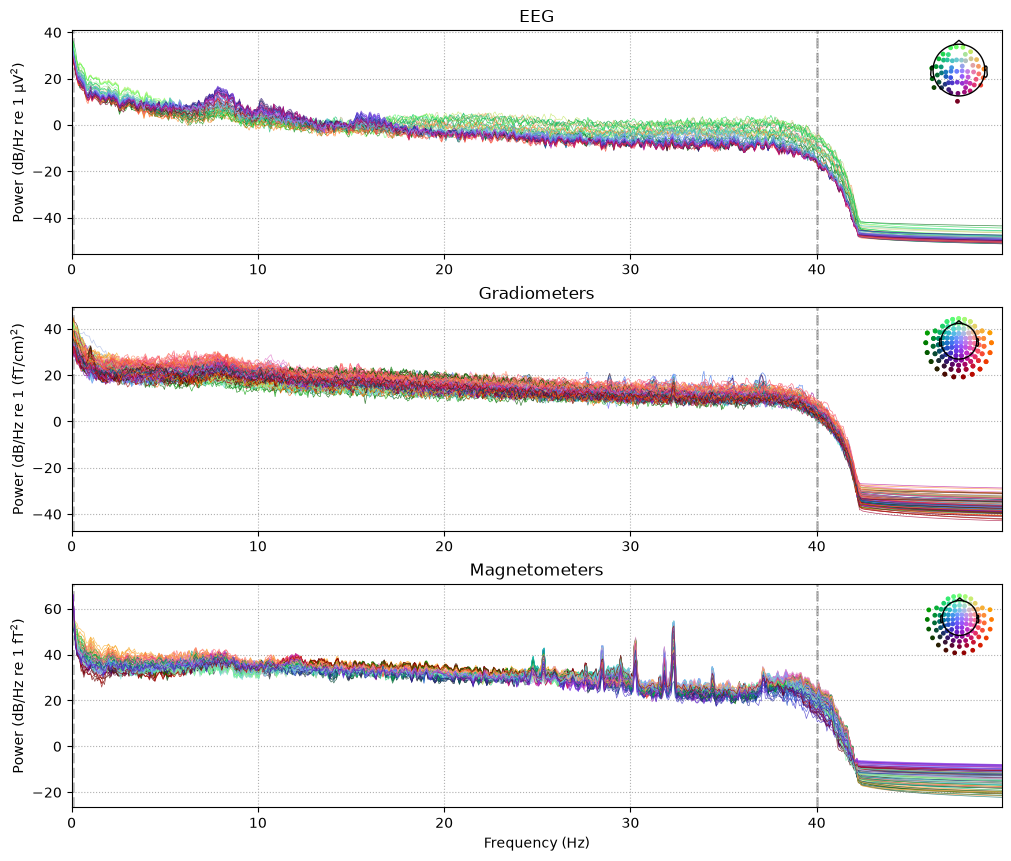

Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


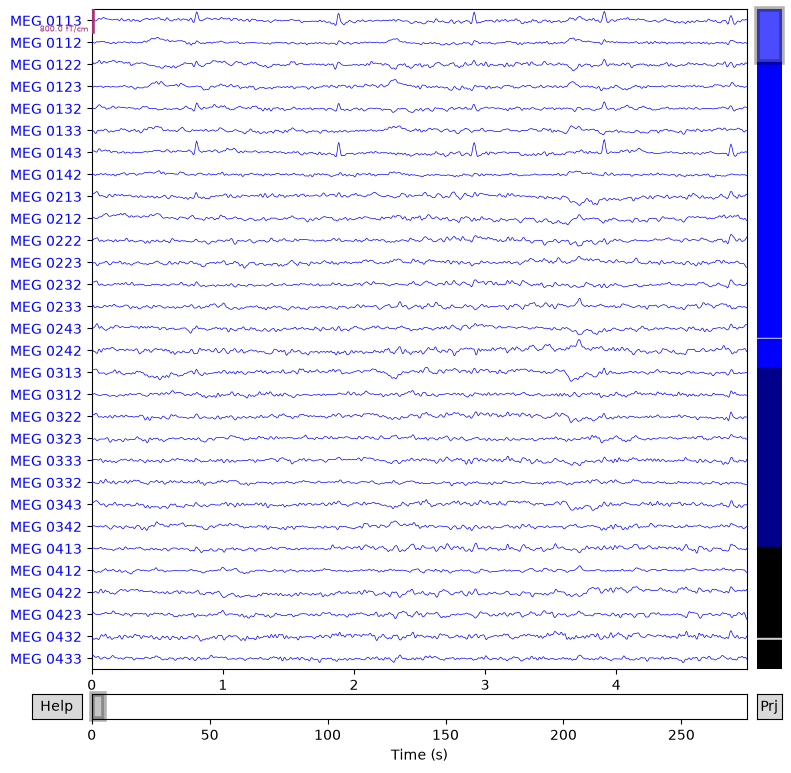

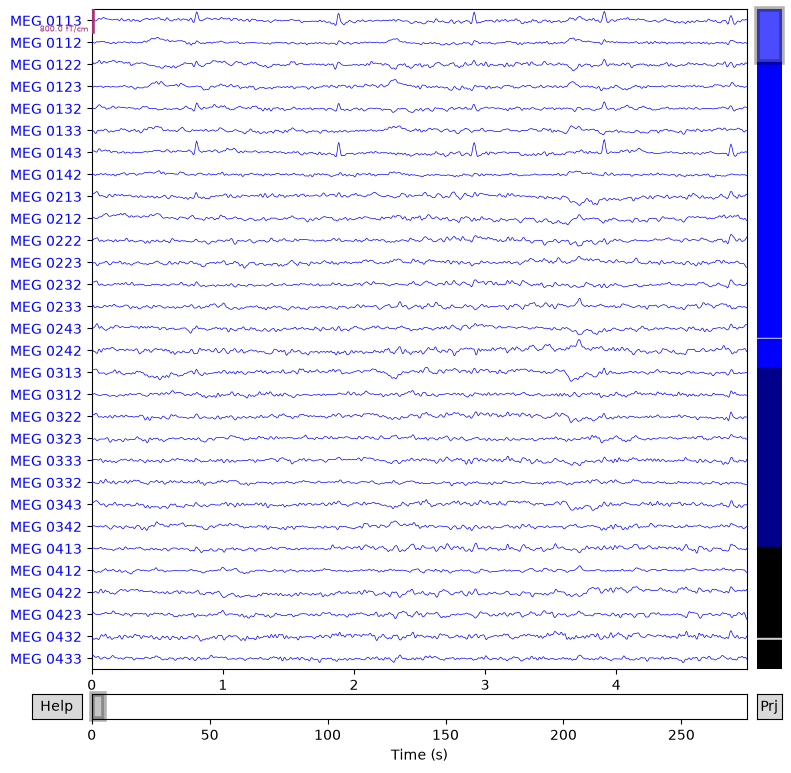

In [7]:
raw.compute_psd(fmax=50).plot(picks="data", exclude="bads", amplitude=False)
raw.plot(duration=5, n_channels=30)

### Preprocessing

example: ICA (independent component analysis)

I can exclude the components we want to remove using the `exclude` parameter below.

NOTE: the steps for determining which components best define artifacts are omitted here. I can learn more abt that here: https://mne.tools/stable/auto_tutorials/preprocessing/40_artifact_correction_ica.html#tut-artifact-ica

Fitting ICA to data using 364 channels (please be patient, this may take a while)
Selecting by number: 20 components
Fitting ICA took 6.2s.
    Using multitaper spectrum estimation with 7 DPSS windows
Not setting metadata
138 matching events found
No baseline correction applied
0 projection items activated
Not setting metadata
138 matching events found
No baseline correction applied
0 projection items activated


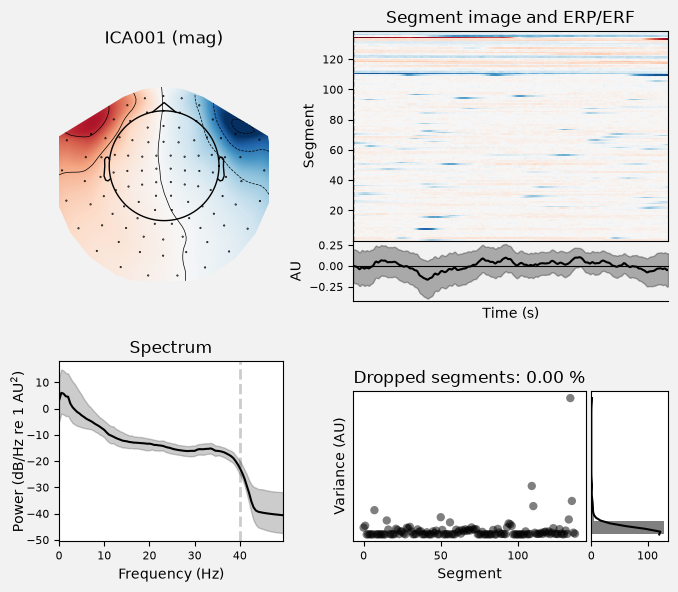

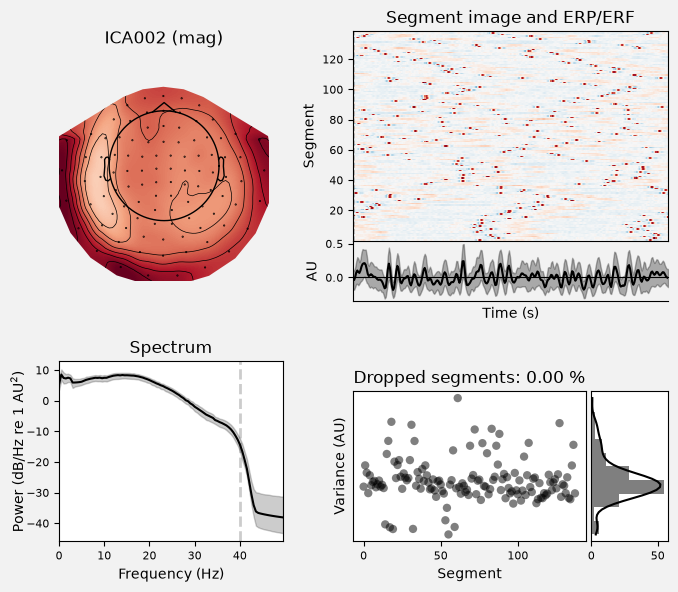

[<Figure size 700x600 with 6 Axes>, <Figure size 700x600 with 6 Axes>]

In [8]:
# set up and fit the ICA
ica = mne.preprocessing.ICA(n_components=20, rng=97, max_iter=800)
ica.fit(raw)
ica.exclude = [1, 2]  # details on how we picked these are omitted here
ica.plot_properties(raw, picks=ica.exclude)

I'll apply the ICA I defined on a copy of the raw data so I can later compare the signals of the two. I also use `load_data` because the `apply` method requires the data to be loaded into memory rather than the disk. after apply I'll plot both the old and new raw data and compare.

Reading 0 ... 41699  =      0.000 ...   277.709 secs...
Applying ICA to Raw instance
    Transforming to ICA space (20 components)
    Zeroing out 2 ICA components
    Projecting back using 364 PCA components
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


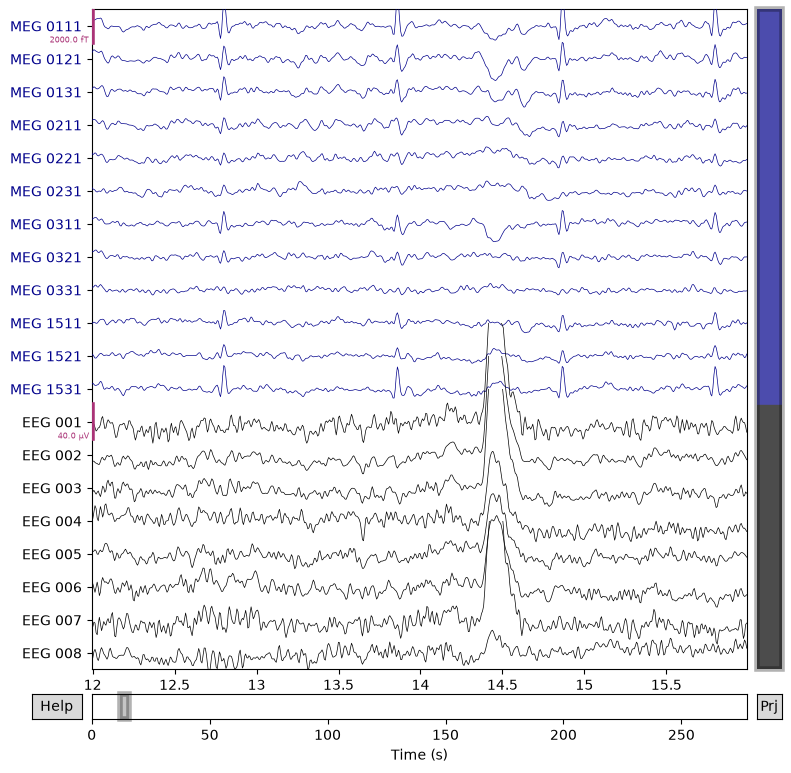

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


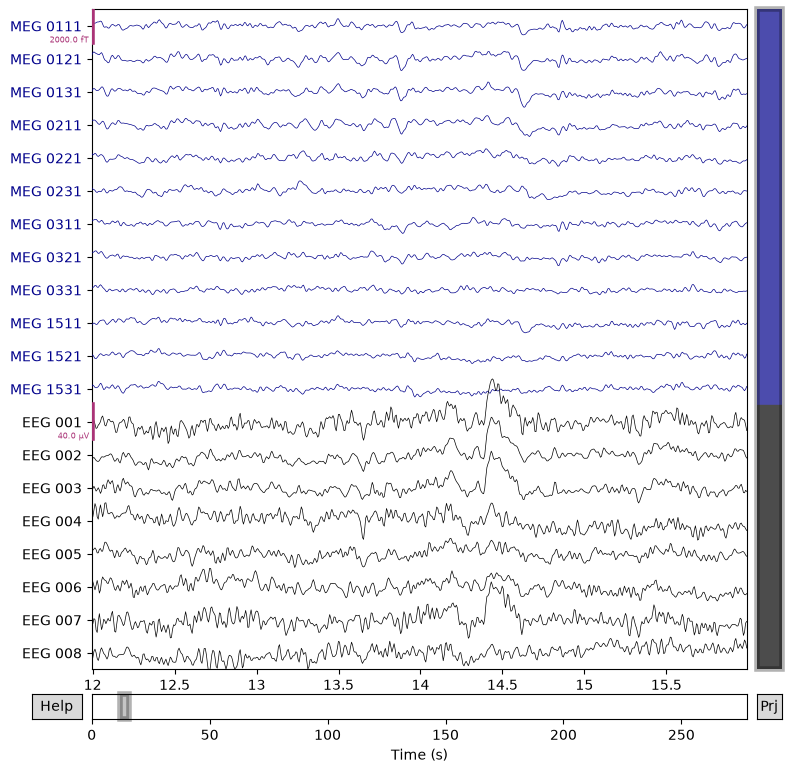

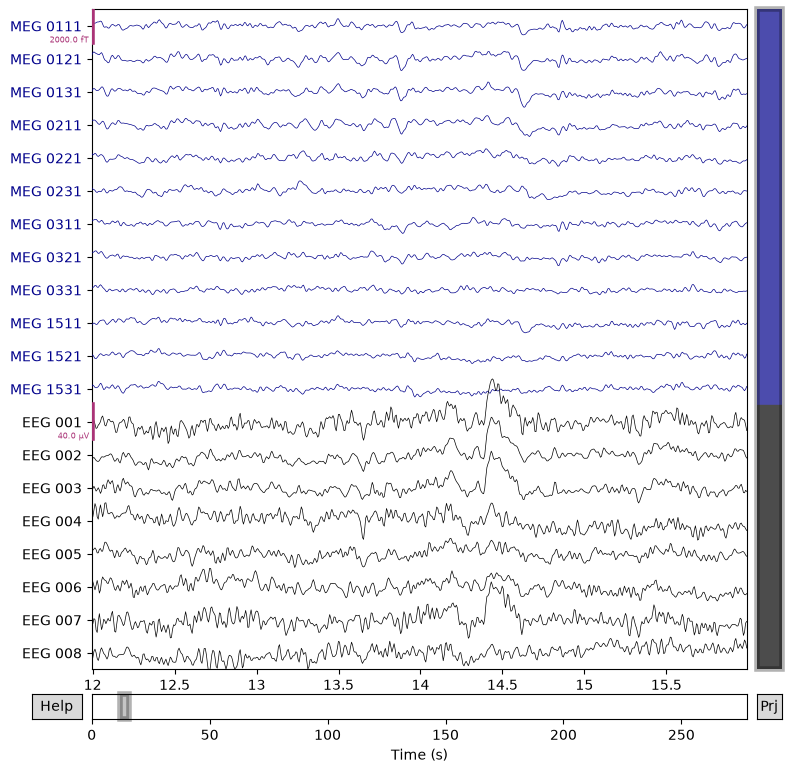

In [9]:
orig_raw = raw.copy() #copy the raw data
raw.load_data() #load the raw data
ica.apply(raw) #apply the ICA to the raw data

# show some frontal channels to clearly illustrate the artifact removal
chs = [
    "MEG 0111",
    "MEG 0121",
    "MEG 0131",
    "MEG 0211",
    "MEG 0221",
    "MEG 0231",
    "MEG 0311",
    "MEG 0321",
    "MEG 0331",
    "MEG 1511",
    "MEG 1521",
    "MEG 1531",
    "EEG 001",
    "EEG 002",
    "EEG 003",
    "EEG 004",
    "EEG 005",
    "EEG 006",
    "EEG 007",
    "EEG 008",
]
chan_idxs = [raw.ch_names.index(ch) for ch in chs] #choose the channels from the raw data
orig_raw.plot(order=chan_idxs, start=12, duration=4) 
raw.plot(order=chan_idxs, start=12, duration=4)

### Some notes on raw data

x-axis - time
y-axis - for any given channel it's amplitude. for MEG magnetometers this is measured in fT (femtotesla), for EEG it's measured in microvolts (), and for MEG gradiometers it's measured in fT/cm, because the gradiometers measure the spatial gradient of the field. 

I'm  guessing that one of the components removed was the heart rate, because the MEG data lost some small, regularly occuring spikes.
